# Mortgage credit risk: modeling data handoff

**Start here for modeling.** This notebook inspects all loans in the Freddie Mac Standard **2008, 2018 and 2023** origination vintages, after cleaning and label construction. It reads the completed Parquet outputs; it does not repeat the large download or ingestion.

The first notebook (`01_data_cleaning_inspection.ipynb`) is the earlier 250,000-loan sample investigation. Those samples are kept separately and are **not pooled into these full-vintage tables**.

The prediction point is the **first observed performance month**, with a 12-month serious-delinquency outcome. This is an acquisition-time research dataset, not an application-time model, accounting ECL, or a fitted model.

Source: [Freddie Mac dataset](https://www.freddiemac.com/research/datasets/sf-loanlevel-dataset), [user guide](https://www.freddiemac.com/fmac-resources/research/pdf/user_guide.pdf). Release 48; performance through June 2026. Local source copies and checksums are in `data/reference/`.

In [1]:
from pathlib import Path
import sys, os, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/modeling_data.py').exists())
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT/'.cache/matplotlib'))
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from IPython.display import display
from src.full_population import data_bytes

DATA = ROOT/'data/modeling'
FULL = ROOT/'data/processed/full_population'
contract = json.loads((DATA/'modeling_contract.json').read_text())
summary = json.loads((FULL/'summary.json').read_text())
assert summary['complete'] and all(contract['invariants'].values())
print(f"Full vintages: {summary['origination_rows']:,} loans; {summary['performance_rows']:,} monthly records")
print(f"Ready labeled examples: {contract['pd_ready_rows']:,}")
print(f"All project data: {data_bytes(ROOT)/1e9:.3f} GB / 10 GB")
display(pd.read_json(ROOT/'data/reference/full_download_manifest.json')[['year','bytes','release','downloaded_date']])

Matplotlib is building the font cache; this may take a moment.


Full vintages: 3,450,330 loans; 145,530,992 monthly records
Ready labeled examples: 3,089,278
All project data: 6.030 GB / 10 GB


,year,bytes,release,downloaded_date
0,2008,920354384,R48-S,2026-11-22
1,2018,855044684,R48-S,2026-11-22
2,2023,447361578,R48-S,2026-11-22


## 1. Cleaning and structural checks

The pipeline validates every raw row against the July 2026 31/35-field layout, preserves source row numbers, applies field-specific missing codes, and writes typed Parquet. Dates use calendar months; categorical IDs and ZIP prefixes stay strings. Missing recoveries remain missing. Each quarter must pass unique origination keys, unique loan-month keys, valid keys and complete origination/performance linkage before publication.

Original signed loss/recovery amounts and extreme valid values remain intact. Value violations are flagged separately. An internal history gap does not automatically invalidate a loan; the target builder checks its actual future window.

In [2]:
quality = pd.read_csv(FULL/'quality_by_quarter.csv')
display(quality)
assert quality.structural_pass.all()
print('Internal gap loans:', f'{quality.loans_with_internal_gaps.sum():,}')
print('Internal missing months:', f'{quality.internal_gap_months.sum():,}')
print('Flagged value violations:', f'{quality.value_violation_count.sum():,}')
audits = pd.concat([pd.read_csv(p).assign(cohort=p.parent.name) for p in FULL.glob('*/cleaning_audit.csv')])
violations = audits[audits.issue.isin(['malformed_count','range_violation_count','code_violation_count']) & audits['count'].gt(0)]
display(violations if len(violations) else pd.DataFrame({'result':['No detected value violations']}))

,cohort,origination_rows,origination_loans,origination_duplicate_keys,origination_invalid_keys,performance_rows,performance_loans,performance_duplicate_keys,performance_invalid_keys,unmatched_performance_rows,unmatched_origination_rows,loans_with_internal_gaps,internal_gap_months,first_reporting_period,last_reporting_period,structural_pass,value_violation_count,origination_identifier_cohort_mismatch_rows,performance_identifier_cohort_mismatch_rows
0,2008Q1,421635,421635,0,0,23849747,421635,0,0,0,0,171,1330,2008-01-01,2026-06-01,True,2,0,0
1,2008Q2,370982,370982,0,0,19540165,370982,0,0,0,0,111,774,2008-03-01,2026-06-01,True,0,0,0
2,2008Q3,221752,221752,0,0,9677069,221752,0,0,0,0,75,409,2008-06-01,2026-06-01,True,0,0,0
3,2008Q4,218777,218777,0,0,9901424,218777,0,0,0,0,46,214,2008-09-01,2026-06-01,True,0,1,209
4,2018Q1,296816,296816,0,0,14486068,296816,0,0,0,0,1,11,2018-01-01,2026-06-01,True,5,0,0
5,2018Q2,364502,364502,0,0,15365379,364502,0,0,0,0,2,31,2018-03-01,2026-06-01,True,0,0,0
6,2018Q3,336669,336669,0,0,13263303,336669,0,0,0,0,3,16,2018-07-01,2026-06-01,True,0,0,0
7,2018Q4,287447,287447,0,0,10255012,287447,0,0,0,0,4,50,2018-10-01,2026-06-01,True,0,0,0
8,2023Q1,186034,186034,0,0,6672759,186034,0,0,0,0,1,3,2023-01-01,2026-06-01,True,0,0,0
9,2023Q2,276113,276113,0,0,9257760,276113,0,0,0,0,1,5,2023-04-01,2026-06-01,True,0,0,0


Internal gap loans: 416
Internal missing months: 2,844
Flagged value violations: 7


,table,field,issue,count,cohort
255,performance,current_interest_bearing_upb,range_violation_count,2,2008Q1
108,origination,original_cltv,range_violation_count,3,2018Q1
136,origination,original_ltv,range_violation_count,2,2018Q1


## 2. Target and chronological partitions

Entry requires a currently performing loan, positive balance, no termination and no flagged origination/baseline value violations. The target is **1** if delinquency reaches at least three months or REO (`RA`) in calendar months **t+1 through t+12**, up to the first observed termination. It is **0** only with all 12 months observed and all statuses known, without an event.

Early payoff, other termination, missing history and unknown status retain a **NULL** target. All loans remain in `features/` and `outcomes/`; only eligible labeled rows enter `pd/`. This complete-outcome sample can be selected: compare censoring by cohort and consider survival/competing-risk methods before generalizing PD to every loan.

- **Train:** 2008 vintage, outcomes mature before 2018.
- **Validation:** 2018 entries before July; use for hyperparameters/feature choices.
- **Calibration:** remaining 2018 entries, outcomes mature before 2023; reserve for calibration.
- **Test:** 2023 vintage, mature 12-month window; keep untouched during development.

The two 2018 subsets are retrospective development partitions and their outcome windows can overlap. All development outcome windows precede test entry. Disclosed cross-split HARP refinancing links are excluded from later ready splits. Other repeat borrowers cannot be identified in these public data.

In [3]:
counts = pd.read_csv(DATA/'summaries/pd_split_counts.csv')
order = ['train','validation','calibration','test']
counts = counts.set_index('split').loc[order].reset_index()
counts['observed_event_rate'] = counts.positive/counts.rows
display(counts)
statuses = pd.read_csv(DATA/'summaries/outcome_status_counts.csv')
display(statuses.pivot(index='outcome_status', columns='split', values='loans').fillna(0).astype(int))
print('Excluded known cross-split refinance loans:', contract['excluded_known_cross_split_refinances'])
display(pd.Series(contract['invariants'], name='passed'))

,split,rows,distinct_loans,positive,first_anchor,last_anchor,observed_event_rate
0,train,1062566,1062566,16933.0,2008-01-01,2016-11-01,0.015936
1,validation,486876,486876,1034.0,2018-01-01,2018-06-01,0.002124
2,calibration,668644,668644,1871.0,2018-07-01,2021-12-01,0.002798
3,test,871192,871192,5549.0,2023-01-01,2025-06-01,0.006369


split,calibration,excluded_time_window,test,train,validation
outcome_status,,,,,
administrative_censoring,0,13,0,0,0
complete_non_event,667147,500,865643,1045633,486459
data_quality_issue,0,0,0,0,4
incomplete_history,0,0,0,1,0
no_positive_entry_balance,654,3,1430,1866,385
not_current_at_entry,305,1,4,464,105
observed_event,1875,1,5549,16933,1044
other_exit_03,0,0,0,11,0
other_exit_96,1258,1,2513,663,755


Excluded known cross-split refinance loans: 1045


train_matures_before_validation    True
development_matures_before_test    True
negatives_have_complete_window     True
negatives_have_known_status        True
Name: passed, dtype: bool

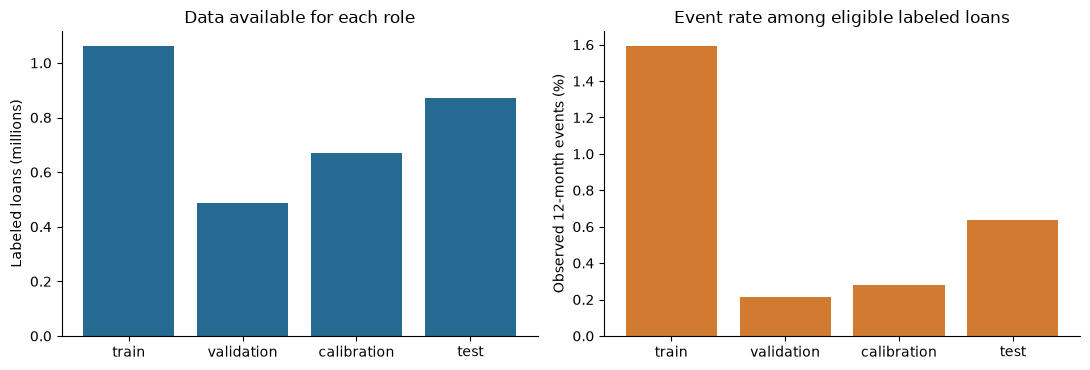

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(counts.split, counts.rows/1e6, color='#246a91')
axes[0].set(ylabel='Labeled loans (millions)', title='Data available for each role')
axes[1].bar(counts.split, 100*counts.observed_event_rate, color='#d17b32')
axes[1].set(ylabel='Observed 12-month events (%)', title='Event rate among eligible labeled loans')
for ax in axes:
    ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(DATA/'summaries/split_overview.png', dpi=140, bbox_inches='tight')
plt.show()

## 3. Load predictors and target safely

Use the **explicit feature list** in `modeling_contract.json`. Never take every non-target column as a predictor: IDs, cohort, date and refinance linkage are metadata. Future histories, exit status and realized losses live in separate tables.

Missing values are intentionally preserved. Fit imputation, scaling, encoding and feature selection on training data only, using an sklearn pipeline or an equivalent model-specific process. Postal codes and all string codes are categorical. Some fields are constant or entirely absent in a vintage; handle this using training data without inspecting test performance. The selected historical release contains retrospective corrections, so true real-time availability is not established.

In [5]:
features = contract['feature_columns']
target = contract['target']
train = pd.read_parquet(DATA/'pd/train.parquet')
X_train = train.loc[:, features]
y_train = train[target].astype('int8')
assert len(train) == int(counts.loc[counts.split.eq('train'), 'rows'].iloc[0])
assert y_train.isin([0,1]).all() and train.loan_identifier.is_unique
assert not set(features).intersection({target,'loan_identifier','actual_loss','observed_ead','resolution_date'})
print('X_train:', X_train.shape, 'y_train:', y_train.shape)
display(pd.DataFrame({'dtype':X_train.dtypes.astype(str), 'missing_fraction':X_train.isna().mean()}).sort_values('missing_fraction', ascending=False))
display(X_train.head())

X_train: (1062566, 30) y_train: (1062566,)


,dtype,missing_fraction
property_valuation_method,str,1.000000
special_eligibility_program,str,1.000000
original_dti,float64,0.022307
classic_fico,float64,0.000761
borrowers_top_coded_2plus,object,0.000582
number_of_borrowers,float64,0.000582
first_time_homebuyer_indicator,str,0.000290
original_cltv,float64,0.000047
original_ltv,float64,0.000047
baseline_remaining_months,float64,0.000024


,classic_fico,first_time_homebuyer_indicator,mortgage_insurance_percentage,number_of_units,occupancy_status,original_cltv,original_dti,original_upb,original_ltv,original_interest_rate,...,harp_indicator,special_eligibility_program,property_valuation_method,interest_only_indicator,baseline_upb,baseline_interest_rate,baseline_loan_age,baseline_remaining_months,months_since_first_payment,anchor_month
0,813.0,N,0.0,1.0,P,37.0,17.0,130000.0,37.0,5.375,...,N,NaN,NaN,N,130000.0,5.375,0,180.0,-1,4
1,771.0,N,0.0,1.0,P,95.0,61.0,272000.0,80.0,5.875,...,N,NaN,NaN,N,272000.0,5.875,0,360.0,-1,2
2,701.0,N,0.0,1.0,P,50.0,36.0,122000.0,50.0,5.125,...,N,NaN,NaN,N,122000.0,5.125,0,240.0,-1,3
3,729.0,N,0.0,1.0,P,73.0,20.0,87000.0,73.0,6.500,...,N,NaN,NaN,N,87000.0,6.500,0,360.0,-1,4
4,796.0,N,0.0,1.0,P,78.0,29.0,148000.0,78.0,5.500,...,N,NaN,NaN,N,148000.0,5.500,0,240.0,-1,3


Use the same feature order for other partitions; fit no preprocessing on them:
```python
validation = pd.read_parquet(DATA/'pd/validation.parquet')
calibration = pd.read_parquet(DATA/'pd/calibration.parquet')
test = pd.read_parquet(DATA/'pd/test.parquet')
X_validation, y_validation = validation[features], validation[target]
# Train model on X_train/y_train; choose settings with validation.
# Fit probability calibration on calibration[features]/calibration[target].
# Evaluate the frozen pipeline once on test[features]/test[target].
```
Report PR-AUC, ROC-AUC, Brier score and calibration by cohort; handle class imbalance without changing the evaluation prevalence. Large time gaps and changing underwriting create substantial distribution shift. No model is trained by this notebook.

## 4. Loss given default and exposure: separate future outcomes

`lgd_ead_outcomes.parquet` contains loans ever observed seriously delinquent. `use_for_lgd` restricts a smaller subset to eligible 12-month events with a disclosed credit-disposition loss and a positive EAD measurement, with resolution timing appropriate for the partition.

EAD is positive UPB in the first serious-delinquency month, otherwise an explicitly marked immediately preceding calendar-month proxy. The observed loss fraction is signed `actual_loss / observed_ead`; negative values and values above one are preserved. Missing losses or unresolved defaults are not zero. A loan may cure and default again before its later disposition, so this fraction does not isolate a single default episode and requires review before LGD modeling. Resolution-only samples are selected and incomplete.

For eventual expected loss, combine a calibrated PD, an explicit LGD assumption/model and an EAD assumption/model consistently at the same horizon. Current or original balance is not automatically future EAD. Economic scenarios, probability calibration and accounting ECL adjustments remain modeling work.

In [6]:
lgd_summary = pd.read_csv(DATA/'summaries/lgd_availability.csv')
display(lgd_summary)
loss = pd.read_parquet(DATA/'lgd_ead_outcomes.parquet')
display(loss.groupby(['split','ead_basis'], dropna=False).size().rename('loans').reset_index())
print('Ready LGD rows:', int(loss.use_for_lgd.fillna(False).sum()))
print('Missing observed loss fraction:', int(loss.observed_loss_fraction.isna().sum()))
display(loss[['loan_identifier','default_date','resolution_date','observed_ead','ead_basis',
              'actual_loss','observed_loss_fraction','use_for_lgd']].head(10))

,split,default_loans,resolved_with_ead,candidate_for_lgd,negative_observed_loss_fraction,observed_loss_fraction_above_one
0,calibration,41700,917,181,108,25
1,excluded_time_window,22,4,0,0,2
2,test,24697,589,328,64,8
3,train,124695,49545,7156,1148,4754
4,validation,28291,664,140,81,24


,split,ead_basis,loans
0,calibration,default_month_upb,41675
1,calibration,previous_month_upb_proxy,25
2,excluded_time_window,default_month_upb,22
3,test,default_month_upb,24687
4,test,previous_month_upb_proxy,10
5,train,default_month_upb,122574
6,train,previous_month_upb_proxy,2121
7,validation,default_month_upb,28247
8,validation,previous_month_upb_proxy,44


Ready LGD rows: 7803
Missing observed loss fraction: 167686


,loan_identifier,default_date,resolution_date,observed_ead,ead_basis,actual_loss,observed_loss_fraction,use_for_lgd
0,F08Q10002214,2009-02-01,2009-10-01,126933.39,default_month_upb,84786.52,0.667961,True
1,F08Q10002219,2013-04-01,NaT,196261.73,default_month_upb,NaN,NaN,False
2,F08Q10002235,2012-02-01,NaT,131335.26,default_month_upb,NaN,NaN,False
3,F08Q10002239,2010-12-01,NaT,171438.23,default_month_upb,NaN,NaN,False
4,F08Q10002242,2011-11-01,2012-05-01,150960.06,default_month_upb,79247.03,0.524954,False
5,F08Q10002268,2009-05-01,2015-12-01,411879.13,default_month_upb,137473.25,0.333771,False
6,F08Q10002280,2009-06-01,NaT,284158.89,default_month_upb,NaN,NaN,False
7,F08Q10002286,2012-01-01,2012-05-01,155934.95,default_month_upb,76196.84,0.488645,False
8,F08Q10002289,2012-03-01,2012-06-01,326462.92,default_month_upb,46322.84,0.141893,False
9,F08Q10002292,2010-05-01,NaT,92609.25,default_month_upb,NaN,NaN,False


## 5. Inspect full histories without loading them into memory

Monthly Parquet files retain all source performance rows. DuckDB can filter or aggregate them directly. The example only reads schema and counts from Parquet metadata; add a WHERE clause on a loan ID for a detailed history.

In [7]:
con = duckdb.connect()
pattern = str(FULL/'*/performance/*.parquet').replace("'", "''")
monthly_count = con.execute(f"SELECT count(*) FROM read_parquet('{pattern}')").fetchone()[0]
assert monthly_count == summary['performance_rows']
print(f'{monthly_count:,} monthly rows are available for alternative landmarks or survival models.')
con.close()
# Release large in-memory objects; no mutation of the saved data.
del train, X_train, y_train, loss

145,530,992 monthly rows are available for alternative landmarks or survival models.


## 6. Reproduce or hand off

See `README.md` for environment setup and download instructions. On a new machine, transfer the repository plus `data/modeling/` for ordinary PD/LGD work. Include `data/processed/full_population/` for monthly-history research, and `data/raw_full/` for complete reproduction. Freddie Mac access and usage terms still apply; local data are excluded from Git.

From the repository root, after placing the three annual Standard full ZIPs in `data/raw_full/`:
```bash
python -m src.full_population --root . --years 2008 2018 2023 --workers 2
python -m src.modeling_data --root .
python scripts/verify_handoff.py
python -m pytest -q
```
Ingestion resumes completed quarters after checking source/code identity and file sizes. Modeling refuses to overwrite an existing completed output. The 10 GB cap includes samples, raw files, references, processed files and modeling outputs. Raw text is never fully extracted. Integrity verification checks the delivered file hashes.